In [1]:
import hashlib
import json
import logging
import random
import re
import sqlite3
import time
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import urljoin
from urllib.robotparser import RobotFileParser

import matplotlib.pyplot as plt
import pandas as pd   #holds table of books
import requests #downloads pages
from bs4 import BeautifulSoup  #parses html(breaks down website into small parts)

In [2]:
BASE_URL = "https://books.toscrape.com"
START_URL = BASE_URL + "/catalogue/page-1.html"

In [3]:
USER_AGENT = "DSC2107-Course-Project (Group 5, B32912@students.ucu.ac.ug)"
DELAY_RANGE = (1.0,2.0)#random wait before EVERY request
RETRY_BACKOFF = (5, 15, 45)# seconds to wait before retry 1, 2, 3
TIMEOUT = 20                    # seconds before a request is abandoned
MAX_REQUESTS = 1200             # hard safety stop for this notebook run

In [4]:
TRIAL_MODE = False # True = only 2 list pages. Set False for the full ~1,000 books
MAX_LIST_PAGES = 2 if TRIAL_MODE else None
EXPECTED_BOOKS = 1000           # what the site says it has

In [5]:
DATA_DIR = Path("data/warmup")
CACHE_DIR = DATA_DIR / "html_cache"     # every downloaded page is kept here
CACHE_DIR.mkdir(parents=True, exist_ok=True)
# Ensure required config values are present even if earlier cells were not run
if "TRIAL_MODE" not in globals():
    TRIAL_MODE = True
if "MAX_LIST_PAGES" not in globals():
    MAX_LIST_PAGES = 2 if TRIAL_MODE else None

logging.basicConfig(
    filename=DATA_DIR / "warmup.log",
    level=logging.INFO,
    format="%(asctime)s %(levelname)s %(message)s",
    force=True,
)
log = logging.getLogger("warmup")

print("TRIAL MODE: only 2 list pages will be scraped." if TRIAL_MODE
      else "FULL MODE: all pages will be scraped.")
print("User-Agent:", USER_AGENT)

FULL MODE: all pages will be scraped.
User-Agent: DSC2107-Course-Project (Group 5, B32912@students.ucu.ac.ug)


In [6]:
## Step 2: Read `robots.txt`
session = requests.Session()
session.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "en"})
stats = {"requests": 0, "cache_hits": 0, "errors": 0}

robots_resp = session.get(BASE_URL + "/robots.txt", timeout=TIMEOUT)
stats["requests"] += 1
print("robots.txt status:", robots_resp.status_code)

rp = RobotFileParser()
if robots_resp.status_code == 200:
    print("-" * 60)
    print(robots_resp.text[:2000])
    print("-" * 60)
    rp.parse(robots_resp.text.splitlines())
    (DATA_DIR / "robots_booksToScrape.txt").write_text(robots_resp.text, encoding="utf-8")
else:
    print("No robots.txt published (or not readable): no rules to parse. We still apply our own limits.")
    rp.parse([])

for test_url in (START_URL, BASE_URL + "/catalogue/a-light-in-the-attic_1000/index.html"):
    print("Allowed?", rp.can_fetch(USER_AGENT, test_url), "->", test_url)

robots.txt status: 404
No robots.txt published (or not readable): no rules to parse. We still apply our own limits.
Allowed? True -> https://books.toscrape.com/catalogue/page-1.html
Allowed? True -> https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html


In [7]:
### Step 3: Build the polite fetch function
class BlockedError(RuntimeError):
    """The site refused us (403/429). We stop and document; we never bypass."""


def fetch(url, use_cache=True):
    """Download `url` politely and return its HTML text (or None if unavailable)."""
    if not rp.can_fetch(USER_AGENT, url):
        raise PermissionError(f"robots.txt disallows {url}")

    cache_file = CACHE_DIR / (hashlib.md5(url.encode()).hexdigest() + ".html")
    if use_cache and cache_file.exists():
        stats["cache_hits"] += 1
        return cache_file.read_text(encoding="utf-8")

    for attempt in range(len(RETRY_BACKOFF) + 1):
        if stats["requests"] >= MAX_REQUESTS:
            raise RuntimeError(f"Request budget of {MAX_REQUESTS} reached")
        time.sleep(random.uniform(*DELAY_RANGE))
        stats["requests"] += 1
        try:
            resp = session.get(url, timeout=TIMEOUT)
        except (requests.Timeout, requests.ConnectionError) as exc:
            stats["errors"] += 1
            log.warning("Network error on %s (attempt %d): %s", url, attempt + 1, exc)
        else:
            if resp.status_code in (403, 429):
                raise BlockedError(f"HTTP {resp.status_code} on {url}")
            if resp.status_code >= 500:
                stats["errors"] += 1
                log.warning("HTTP %d on %s (attempt %d)", resp.status_code, url, attempt + 1)
            elif resp.status_code >= 400:
                log.error("HTTP %d on %s: skipping", resp.status_code, url)
                return None
            else:
                resp.encoding = "utf-8"          # fixes the Â£ problem
                cache_file.write_text(resp.text, encoding="utf-8")
                return resp.text
        if attempt < len(RETRY_BACKOFF):
            time.sleep(RETRY_BACKOFF[attempt])

    log.error("Giving up on %s", url)
    return None


def text_or_none(node):
    """Safe getter: the text of a tag, or None if the tag was not found."""
    return node.get_text(strip=True) if node is not None else None


print("fetch() ready")

fetch() ready


In [8]:
## Step 4: Reconnaissance: look at the HTML before writing any parser
""" cell below fetches page 1 and prints the HTML of **one book card**, so you can see the structure we are about to parse."""
html_page1 = fetch(START_URL)
soup_demo = BeautifulSoup(html_page1, "html.parser")

print("Book cards on this page:", len(soup_demo.select("article.product_pod")))
print("Pagination text:", text_or_none(soup_demo.select_one("li.current")))
print("Next link:", soup_demo.select_one("li.next a")["href"])
print()
print(soup_demo.select_one("article.product_pod").prettify()[:1500])

Book cards on this page: 20
Pagination text: Page 1 of 50
Next link: page-2.html

<article class="product_pod">
 <div class="image_container">
  <a href="a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="../media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   £51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



In [9]:
## Step 5: Parse one list page
"""*What we are doing:** a function that takes the HTML of one list page and returns
(a) the books on it and (b) the URL of the next page."""


def parse_listing_page(html, page_url):
    """Return (books_on_page, next_page_url_or_None) for one list page."""
    soup = BeautifulSoup(html, "html.parser")
    books = []
    for card in soup.select("article.product_pod"):
        link = card.select_one("h3 a")
        if link is None or not link.get("href"):
            log.warning("Card without a link on %s", page_url)
            continue
        books.append({
            "title_list": link.get("title") or link.get_text(strip=True),
            "detail_url": urljoin(page_url, link["href"]),
            "list_price_raw": text_or_none(card.select_one("p.price_color")),
        })
    nxt = soup.select_one("li.next a")
    next_url = urljoin(page_url, nxt["href"]) if nxt else None
    return books, next_url


books_demo, next_demo = parse_listing_page(html_page1, START_URL)
print(len(books_demo), "books parsed. Next page:", next_demo)
pd.DataFrame(books_demo).head()

20 books parsed. Next page: https://books.toscrape.com/catalogue/page-2.html


,title_list,detail_url,list_price_raw
0,A Light in the Attic,https://books.toscrape.com/catalogue/a-light-i...,£51.77
1,Tipping the Velvet,https://books.toscrape.com/catalogue/tipping-t...,£53.74
2,Soumission,https://books.toscrape.com/catalogue/soumissio...,£50.10
3,Sharp Objects,https://books.toscrape.com/catalogue/sharp-obj...,£47.82
4,Sapiens: A Brief History of Humankind,https://books.toscrape.com/catalogue/sapiens-a...,£54.23


In [ ]:
### Step 6: Pagination: collect every book link

def collect_book_links():
    url, page_no, seen, listing = START_URL, 1, set(), []
    while url and (MAX_LIST_PAGES is None or page_no <= MAX_LIST_PAGES):
        html = fetch(url)
        if html is None:
            log.error("List page %d could not be fetched; stopping pagination", page_no)
            break
        books, next_url = parse_listing_page(html, url)
        new = [b for b in books if b["detail_url"] not in seen]
        if not new:
            log.warning("Page %d produced no new books; stopping (loop guard)", page_no)
            break
        for b in new:
            b["list_page"] = page_no
            seen.add(b["detail_url"])
        listing.extend(new)
        if page_no % 10 == 0 or next_url is None:
            print(f"page {page_no}: {len(listing)} books so far | requests={stats['requests']} cache hits={stats['cache_hits']}")
        url, page_no = next_url, page_no + 1
    return listing


listing = collect_book_links()
print("\nBook links collected:", len(listing))
if not TRIAL_MODE:
    assert len(listing) == EXPECTED_BOOKS, f"Expected {EXPECTED_BOOKS}, got {len(listing)}"
    print("Coverage check passed: all 1,000 books found.")

page 10: 200 books so far | requests=11 cache hits=1
page 20: 400 books so far | requests=21 cache hits=1
page 30: 600 books so far | requests=31 cache hits=1


In [ ]:
## Step 7: Parse one detail page

"""hat we are doing:** extracting the full record of a single book from its own page."""

RATING_WORDS = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}


def parse_detail_page(html, url):
    """Return one raw record (dict) for a book detail page. Never raises on missing fields."""
    soup = BeautifulSoup(html, "html.parser")

    crumbs = [li.get_text(strip=True) for li in soup.select("ul.breadcrumb li")]
    star = soup.select_one("p.star-rating")
    star_classes = star.get("class", []) if star else []

    desc_anchor = soup.select_one("#product_description")
    desc_tag = desc_anchor.find_next_sibling("p") if desc_anchor else None

    img = soup.select_one("div.item.active img") or soup.select_one("div.carousel img")

    table = {}
    for row in soup.select("table.table-striped tr"):
        if row.th is not None and row.td is not None:
            table[row.th.get_text(strip=True)] = row.td.get_text(strip=True)

    return {
        "url": url,
        "title": text_or_none(soup.select_one("div.product_main h1")),
        "category": crumbs[2] if len(crumbs) >= 3 else None,
        "rating": next((RATING_WORDS[c] for c in star_classes if c in RATING_WORDS), None),
        "price_raw": text_or_none(soup.select_one("div.product_main p.price_color")),
        "description": text_or_none(desc_tag),
        "image_url": urljoin(url, img["src"]) if img is not None and img.get("src") else None,
        "upc": table.get("UPC"),
        "product_type": table.get("Product Type"),
        "price_excl_tax_raw": table.get("Price (excl. tax)"),
        "price_incl_tax_raw": table.get("Price (incl. tax)"),
        "tax_raw": table.get("Tax"),
        "availability_raw": table.get("Availability"),
        "n_reviews_raw": table.get("Number of reviews"),
        "scraped_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }


first_url = listing[0]["detail_url"]
demo_record = parse_detail_page(fetch(first_url), first_url)
for key, value in demo_record.items():
    shown = (value[:80] + "...") if isinstance(value, str) and len(value) > 80 else value
    print(f"{key:22} {shown}")

url                    https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html
title                  A Light in the Attic
category               Poetry
rating                 3
price_raw              £51.77
description            It's hard to imagine a world without A Light in the Attic. This now-classic coll...
image_url              https://books.toscrape.com/media/cache/fe/72/fe72f0532301ec28892ae79a629a293c.jp...
upc                    a897fe39b1053632
product_type           Books
price_excl_tax_raw     £51.77
price_incl_tax_raw     £51.77
tax_raw                £0.00
availability_raw       In stock (22 available)
n_reviews_raw          0
scraped_at             2026-10-11T14:26:43+00:00


In [ ]:
## Step 8: Scrape all detail pages

"""**What we are doing:** looping over every book link, fetching its detail page and parsing it."""

def scrape_all_details(listing_rows):
    records, failed = [], []
    t0 = time.time()
    for i, row in enumerate(listing_rows, start=1):
        url = row["detail_url"]
        try:
            html = fetch(url)
            if html is None:
                failed.append((url, "no html"))
                continue
            rec = parse_detail_page(html, url)
            rec["list_page"] = row["list_page"]
            records.append(rec)
        except BlockedError:
            print("BLOCKED. Stopping now and keeping what we have. Document this and reduce the rate.")
            log.error("Blocked at %s", url)
            break
        except Exception as exc:                       # one bad page must not kill the run
            log.exception("Parse failure on %s", url)
            failed.append((url, repr(exc)))
        if i % 50 == 0:
            print(f"{i}/{len(listing_rows)} done | {time.time() - t0:5.0f}s | requests={stats['requests']} "
                  f"cache hits={stats['cache_hits']} failed={len(failed)}")
    return records, failed


records, failed = scrape_all_details(listing)

if failed:                                             # one retry pass
    print(f"Retrying {len(failed)} failures...")
    retry_rows = [r for r in listing if r["detail_url"] in {u for u, _ in failed}]
    more, failed = scrape_all_details(retry_rows)
    records += more

print(f"\nScraped {len(records)} books | still failing: {len(failed)} | stats: {stats}")

50/1000 done |    29s | requests=101 cache hits=44 failed=0
100/1000 done |   151s | requests=151 cache hits=44 failed=0
150/1000 done |   264s | requests=201 cache hits=44 failed=0
200/1000 done |   390s | requests=251 cache hits=44 failed=0
250/1000 done |   499s | requests=301 cache hits=44 failed=0
300/1000 done |   610s | requests=351 cache hits=44 failed=0
350/1000 done |   720s | requests=401 cache hits=44 failed=0
400/1000 done |   830s | requests=451 cache hits=44 failed=0
450/1000 done |   937s | requests=501 cache hits=44 failed=0
500/1000 done |  1042s | requests=551 cache hits=44 failed=0
550/1000 done |  1149s | requests=601 cache hits=44 failed=0
600/1000 done |  1255s | requests=651 cache hits=44 failed=0
650/1000 done |  1363s | requests=701 cache hits=44 failed=0
700/1000 done |  1475s | requests=751 cache hits=44 failed=0
750/1000 done |  1586s | requests=801 cache hits=44 failed=0
800/1000 done |  1695s | requests=851 cache hits=44 failed=0
850/1000 done |  1805s | 

In [ ]:
## Step 9: Save the raw data
run_date = datetime.now(timezone.utc).strftime("%Y-%m-%d")
raw_json = DATA_DIR / f"books_raw_{run_date}.json"
raw_csv = DATA_DIR / f"books_raw_{run_date}.csv"

raw_json.write_text(json.dumps(records, indent=1, ensure_ascii=False), encoding="utf-8")
pd.DataFrame(records).to_csv(raw_csv, index=False, encoding="utf-8")
print("Saved:", raw_json, "and", raw_csv)


Saved: data\warmup\books_raw_2026-10-11.json and data\warmup\books_raw_2026-10-11.csv


In [ ]:
## Step 10: Validate the data
"""Validating the dataset *before* trusting it. Good analysts do this every time."""

raw_df = pd.DataFrame(records)
print("Rows:", len(raw_df))
print("Distinct UPCs:", raw_df["upc"].nunique())
print("Encoding problems (Â in prices):", int(raw_df["price_raw"].str.contains("Â", na=False).sum()))

print("\nMissing values per column:")
print(raw_df.isna().sum().to_string())

print("\nSample of raw price/availability strings:")
print(raw_df[["price_raw", "availability_raw", "rating"]].head(5).to_string(index=False))

if not TRIAL_MODE:
    assert len(raw_df) == EXPECTED_BOOKS, "Row count mismatch"
    assert raw_df["upc"].nunique() == EXPECTED_BOOKS, "Duplicate or missing UPCs"
    assert raw_df["rating"].between(1, 5).all(), "Rating outside 1-5"
    print("\nAll validation checks passed.")




Rows: 1000
Distinct UPCs: 1000
Encoding problems (Â in prices): 0

Missing values per column:
url                   0
title                 0
category              0
rating                0
price_raw             0
description           2
image_url             0
upc                   0
product_type          0
price_excl_tax_raw    0
price_incl_tax_raw    0
tax_raw               0
availability_raw      0
n_reviews_raw         0
scraped_at            0
list_page             0

Sample of raw price/availability strings:
price_raw        availability_raw  rating
   £51.77 In stock (22 available)       3
   £53.74 In stock (20 available)       1
   £50.10 In stock (20 available)       1
   £47.82 In stock (20 available)       4
   £54.23 In stock (20 available)       5

All validation checks passed.


In [ ]:
## Step 11: Clean the data
def parse_price(raw):
    """'£51.77' -> 51.77 ; unparseable -> None"""
    if raw is None:
        return None
    digits = re.sub(r"[^\d.]", "", str(raw))
    return float(digits) if digits else None


def parse_stock(raw):
    """'In stock (22 available)' -> (True, 22)"""
    if raw is None:
        return None, None
    m = re.search(r"\((\d+)\s+available\)", raw)
    return ("in stock" in raw.lower()), (int(m.group(1)) if m else None)


def clean_books(df):
    out = df.copy()
    out["price_gbp"] = out["price_raw"].map(parse_price)
    out["price_excl_tax_gbp"] = out["price_excl_tax_raw"].map(parse_price)
    out["price_incl_tax_gbp"] = out["price_incl_tax_raw"].map(parse_price)
    out["tax_gbp"] = out["tax_raw"].map(parse_price)
    stock = out["availability_raw"].map(parse_stock)
    out["in_stock"] = stock.map(lambda t: t[0])
    out["stock_count"] = stock.map(lambda t: t[1])
    out["n_reviews"] = pd.to_numeric(out["n_reviews_raw"], errors="coerce").astype("Int64")
    out["rating"] = out["rating"].astype("Int64")
    out["category"] = out["category"].str.strip().str.title()
    out["has_description"] = out["description"].notna()
    out = out.drop_duplicates(subset="upc", keep="first")
    keep = ["upc", "title", "category", "rating", "price_gbp", "price_excl_tax_gbp",
            "price_incl_tax_gbp", "tax_gbp", "in_stock", "stock_count", "n_reviews",
            "has_description", "description", "product_type", "image_url", "url",
            "list_page", "scraped_at"]
    return out[keep].reset_index(drop=True)


books = clean_books(raw_df)
print(books.dtypes.to_string())
books.head()


upc                    object
title                  object
category               object
rating                  Int64
price_gbp             float64
price_excl_tax_gbp    float64
price_incl_tax_gbp    float64
tax_gbp               float64
in_stock                 bool
stock_count             int64
n_reviews               Int64
has_description          bool
description            object
product_type           object
image_url              object
url                    object
list_page               int64
scraped_at             object


,upc,title,category,rating,price_gbp,price_excl_tax_gbp,price_incl_tax_gbp,tax_gbp,in_stock,stock_count,n_reviews,has_description,description,product_type,image_url,url,list_page,scraped_at
0,a897fe39b1053632,A Light in the Attic,Poetry,3,51.77,51.77,51.77,0.0,True,22,0,True,It's hard to imagine a world without A Light i...,Books,https://books.toscrape.com/media/cache/fe/72/f...,https://books.toscrape.com/catalogue/a-light-i...,1,2026-10-11T14:38:03+00:00
1,90fa61229261140a,Tipping the Velvet,Historical Fiction,1,53.74,53.74,53.74,0.0,True,20,0,True,"""Erotic and absorbing...Written with starling ...",Books,https://books.toscrape.com/media/cache/08/e9/0...,https://books.toscrape.com/catalogue/tipping-t...,1,2026-10-11T14:38:03+00:00
2,6957f44c3847a760,Soumission,Fiction,1,50.10,50.10,50.10,0.0,True,20,0,True,"Dans une France assez proche de la nôtre, un h...",Books,https://books.toscrape.com/media/cache/ee/cf/e...,https://books.toscrape.com/catalogue/soumissio...,1,2026-10-11T14:38:03+00:00
3,e00eb4fd7b871a48,Sharp Objects,Mystery,4,47.82,47.82,47.82,0.0,True,20,0,True,"WICKED above her hipbone, GIRL across her hear...",Books,https://books.toscrape.com/media/cache/c0/59/c...,https://books.toscrape.com/catalogue/sharp-obj...,1,2026-10-11T14:38:03+00:00
4,4165285e1663650f,Sapiens: A Brief History of Humankind,History,5,54.23,54.23,54.23,0.0,True,20,0,True,From a renowned historian comes a groundbreaki...,Books,https://books.toscrape.com/media/cache/ce/5f/c...,https://books.toscrape.com/catalogue/sapiens-a...,1,2026-10-11T14:38:03+00:00


In [ ]:
## Step 12: Store it in SQLite
"**What we are doing:** loading the cleaned data into a small **relational database** with two tables."

DB_PATH = DATA_DIR / "books_warmup.db"
if DB_PATH.exists():
    DB_PATH.unlink()                      # rebuild from scratch so this cell is repeatable

conn = sqlite3.connect(DB_PATH)
conn.executescript("""
PRAGMA foreign_keys = ON;
CREATE TABLE categories (
    category_id INTEGER PRIMARY KEY,
    name        TEXT NOT NULL UNIQUE
);
CREATE TABLE books (
    book_id      INTEGER PRIMARY KEY,
    upc          TEXT NOT NULL UNIQUE,
    title        TEXT,
    category_id  INTEGER REFERENCES categories(category_id),
    rating       INTEGER CHECK (rating BETWEEN 1 AND 5),
    price_gbp    REAL,
    tax_gbp      REAL,
    in_stock     INTEGER,
    stock_count  INTEGER,
    n_reviews    INTEGER,
    description  TEXT,
    url          TEXT,
    scraped_at   TEXT
);
""")

conn.executemany("INSERT INTO categories(name) VALUES (?)",
                 [(c,) for c in sorted(books["category"].dropna().unique())])
cat_ids = dict(conn.execute("SELECT name, category_id FROM categories").fetchall())


def py(v):
    """pandas NA/NaN -> None, numpy numbers -> plain Python (SQLite needs this)."""
    if pd.isna(v):
        return None
    return v.item() if hasattr(v, "item") else v


rows = [(py(r.upc), py(r.title), cat_ids.get(r.category), py(r.rating), py(r.price_gbp),
         py(r.tax_gbp), None if pd.isna(r.in_stock) else int(r.in_stock), py(r.stock_count),
         py(r.n_reviews), py(r.description), py(r.url), py(r.scraped_at))
        for r in books.itertuples()]
conn.executemany("""INSERT INTO books (upc, title, category_id, rating, price_gbp, tax_gbp, in_stock,
                    stock_count, n_reviews, description, url, scraped_at)
                    VALUES (?,?,?,?,?,?,?,?,?,?,?,?)""", rows)
conn.commit()

query = """
SELECT c.name AS category, COUNT(*) AS n_books, ROUND(AVG(b.price_gbp), 2) AS avg_price_gbp
FROM books b JOIN categories c ON c.category_id = b.category_id
GROUP BY c.name ORDER BY n_books DESC LIMIT 8;
"""
print("Books in database:", conn.execute("SELECT COUNT(*) FROM books").fetchone()[0])
pd.read_sql_query(query, conn)

Books in database: 1000


,category,n_books,avg_price_gbp
0,Default,152,34.39
1,Nonfiction,110,34.26
2,Sequential Art,75,34.57
3,Add A Comment,67,35.80
4,Fiction,65,36.07
5,Young Adult,54,35.45
6,Fantasy,48,39.59
7,Romance,35,33.93


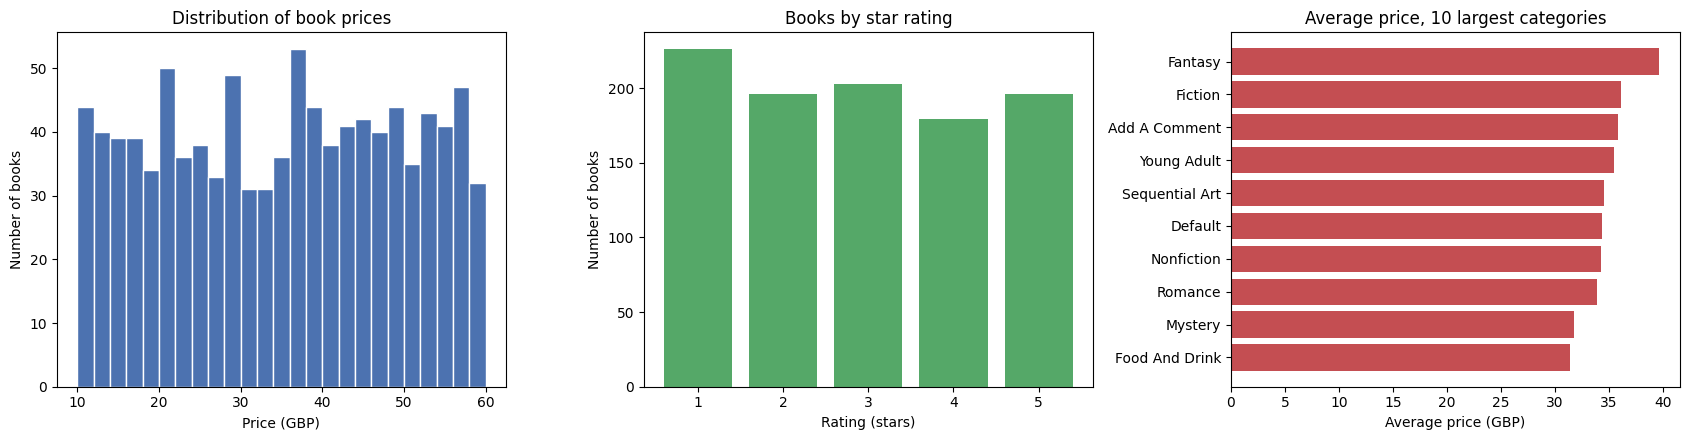

Cheapest:       An Abundance of Katherines (GBP 10.00)
Most expensive: The Perfect Play (Play by Play #1) (GBP 59.99)


In [ ]:
## Step 13: Quick analysis, then reflection

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].hist(books["price_gbp"].dropna(), bins=25, color="#4C72B0", edgecolor="white")
axes[0].set(title="Distribution of book prices", xlabel="Price (GBP)", ylabel="Number of books")

rating_counts = books["rating"].value_counts().sort_index()
axes[1].bar(rating_counts.index.astype(str), rating_counts.values, color="#55A868")
axes[1].set(title="Books by star rating", xlabel="Rating (stars)", ylabel="Number of books")

top = books["category"].value_counts().head(10).index
avg = books[books["category"].isin(top)].groupby("category")["price_gbp"].mean().sort_values()
axes[2].barh(avg.index, avg.values, color="#C44E52")
axes[2].set(title="Average price, 10 largest categories", xlabel="Average price (GBP)")

plt.tight_layout()
plt.show()

cheapest = books.loc[books["price_gbp"].idxmin()]
priciest = books.loc[books["price_gbp"].idxmax()]
print(f"Cheapest:       {cheapest['title']} (GBP {cheapest['price_gbp']:.2f})")
print(f"Most expensive: {priciest['title']} (GBP {priciest['price_gbp']:.2f})")